# Curves: bootstrapping, forwards and carry

Family 18. Interest rates below are synthetic decimal quotes. Discount factors
are date-based, zero/forward rates are continuously compounded, and curve
extrapolation is deliberately disabled.

In [1]:
from pathlib import Path
import sys
root = Path.cwd()
if not (root / 'convexity').exists():
    root = root.parent
if str(root) not in sys.path:
    sys.path.insert(0, str(root))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from convexity.math import contracts as ct, curves as cv, pricing as pr
rng = np.random.default_rng(1800)
ref, expiry = '2026-01-01', '2027-01-01'
discount, dividend = cv.flat_curve(ref, .04), cv.flat_curve(ref, .01)
model = pr.BlackScholesModel(100., discount, dividend, .2)
plt.rcParams.update({'figure.figsize': (9, 3.5), 'figure.dpi': 110,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .2})
print('Interpreter:', sys.executable)

Interpreter: /home/ethan/miniconda3/envs/quant/bin/python


## A shaped zero curve

Zero rates and interval forwards encode different information. A forward rate
is calculated from two discounts; it is not a forecast of the future realized rate.

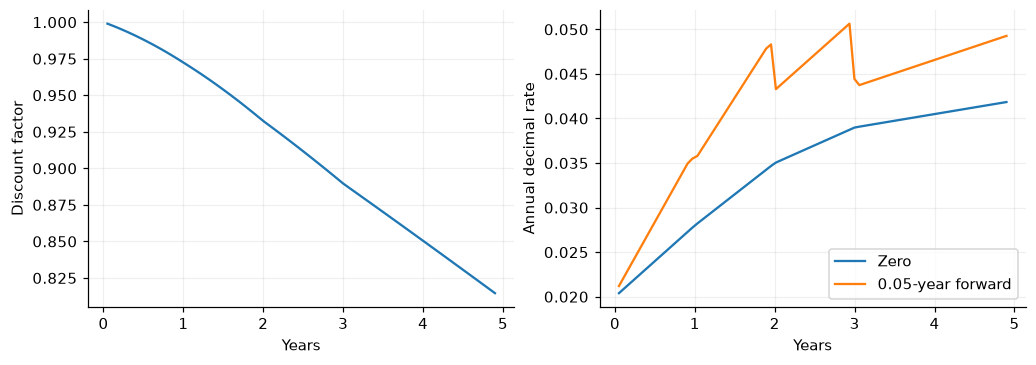

In [2]:
dates=[ref,'2027-01-01','2028-01-01','2029-01-01','2031-01-01']
curve=cv.zero_curve(dates,[.02,.028,.035,.039,.042])
times=np.linspace(.05,4.9,80)
fig,axes=plt.subplots(1,2,figsize=(11,3.5))
axes[0].plot(times,[curve.discount(t) for t in times]);axes[0].set(xlabel='Years',ylabel='Discount factor')
axes[1].plot(times,[curve.zero_rate(t) for t in times],label='Zero')
axes[1].plot(times,[curve.forward_rate(t,t+.05) for t in times],label='0.05-year forward')
axes[1].set(xlabel='Years',ylabel='Annual decimal rate');axes[1].legend();plt.show()

## Reprice bootstrap quotes without vendor helpers

Quotes use explicit day counts and settlement conventions. The returned curve
and its quote residuals are calibrated snapshots. Convexity manages native
helpers and valuation dates internally.

,Months,Quote,Repriced,Residual
0,1,0.025,0.025,1.948372e-12
1,3,0.027,0.027,6.879705e-13
2,6,0.030,0.030,-3.053113e-16
3,12,0.034,0.034,-5.967449e-15


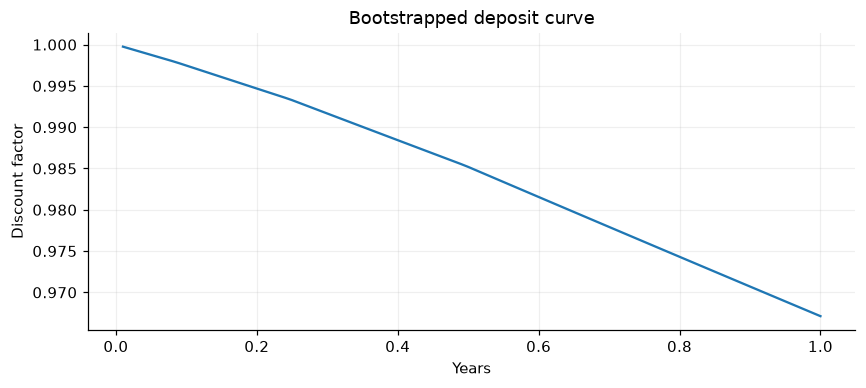

In [3]:
quotes=[(1,.025),(3,.027),(6,.03),(12,.034)]
helpers=[cv.deposit_quote(rate,f"{months}M") for months,rate in quotes]
boot=cv.bootstrap(ref,helpers)
comparison=pd.DataFrame({'Months':[x[0] for x in quotes],'Quote':[x[1] for x in quotes],
                         'Repriced':np.array([x[1] for x in quotes])+boot.calibration_errors})
comparison['Residual']=comparison.Repriced-comparison.Quote
display(comparison)
grid=np.linspace(.01,1,100)
plt.plot(grid,[boot.discount(t) for t in grid]);plt.xlabel('Years');plt.ylabel('Discount factor');plt.title('Bootstrapped deposit curve');plt.show()

## Separate financing, dividend and storage assumptions

Carry uses deterministic curves. Futures basis is the difference from a
separately supplied futures price; this calculation does not assume a stochastic
rate convexity adjustment.

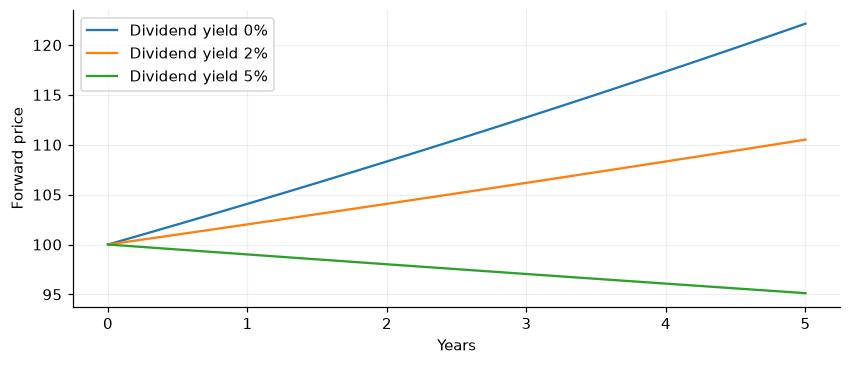

,Storage rate,Convenience yield,One-year forward
0,0.00,0.00,104.081077
1,0.03,0.00,107.250818
2,0.03,0.02,105.127110


In [4]:
maturities=np.linspace(0,5,80)
for yield_ in [0.,.02,.05]:
    div=cv.flat_curve(ref,yield_)
    plt.plot(maturities,[cv.forward_price(100,t,discount,dividend=div) for t in maturities],label=f'Dividend yield {yield_:.0%}')
plt.xlabel('Years');plt.ylabel('Forward price');plt.legend();plt.show()
display(pd.DataFrame([{'Storage rate':u,'Convenience yield':y,'One-year forward':cv.forward_price(100,1,discount,storage_rate=u,convenience_yield=y)} for u,y in [(0,0),(.03,0),(.03,.02)]]))

## Scope of the evidence

These are generated-data experiments under the stated models, not market forecasts or universal model rankings. Numerical errors, backend restrictions and measure assumptions are documented in the [financial catalog](../docs/financial_mathematics.md) and [QA record](../docs/financial_qa.md). Automated adversarial checks live in `tests/math/finance/`.